In [1]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

In [2]:
sim = AerSimulator()
shots = 100

In [3]:
qc_a = QuantumCircuit(2, 2)
qc_a.h(0)
qc_a.cx(0, 1)
qc_a.measure([0, 1], [0, 1])

In [4]:
qc_b = QuantumCircuit(2, 2)
qc_b.h(0)
qc_b.cx(0, 1)
qc_b.x(1)            # the only change from Part A
qc_b.measure([0, 1], [0, 1])

Part A circuit


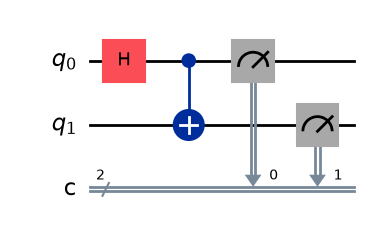

Part B circuit


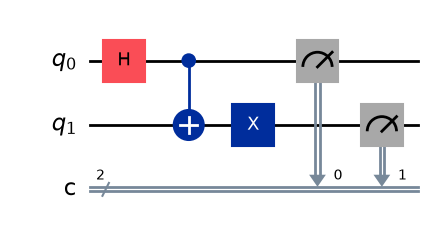

In [5]:
print("Part A circuit")
display(qc_a.draw('mpl'))
print("Part B circuit")
display(qc_b.draw('mpl'))

In [6]:
counts_a = sim.run(qc_a, shots=shots).result().get_counts()
counts_b = sim.run(qc_b, shots=shots).result().get_counts()

print("Part A:", counts_a)
print("Part B:", counts_b)

Part A: {'00': 54, '11': 46}
Part B: {'10': 53, '01': 47}


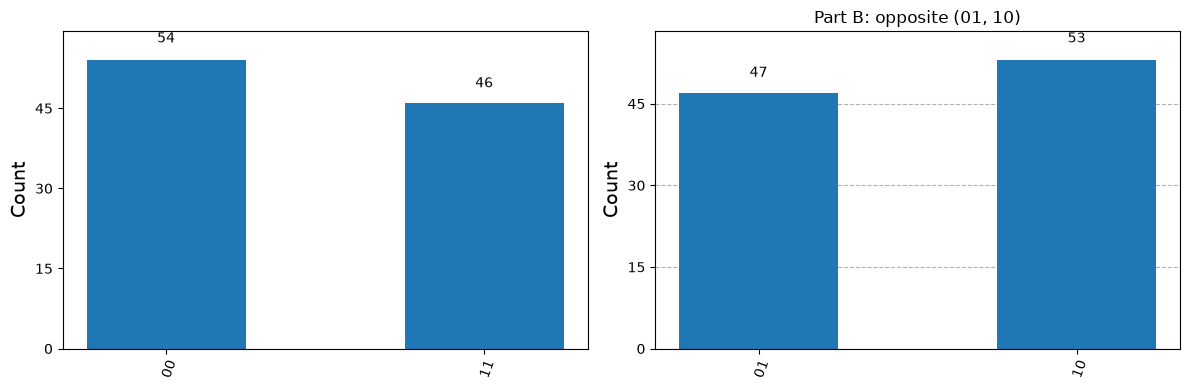

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_histogram(counts_a, ax=axes[0], title="Part A: correlated (00, 11)")
plot_histogram(counts_b, ax=axes[1], title="Part B: opposite (01, 10)")
plt.tight_layout()
plt.show()

In [8]:
plot_histogram([counts_a, counts_b], legend=["Part A", "Part B"])
plt.show()

In [9]:
def make_circuit(opposite=False):
    qc = QuantumCircuit(2, 2)
    qc.h(0)
    qc.cx(0, 1)
    if opposite:
        qc.x(1)
    qc.measure([0, 1], [0, 1])
    return qc

print("Correlated:", sim.run(make_circuit(False), shots=100).result().get_counts())
print("Opposite:  ", sim.run(make_circuit(True), shots=100).result().get_counts())

Correlated: {'00': 41, '11': 59}
Opposite:   {'01': 57, '10': 43}
